# Project Deliverable 1: Data Collection, Cleaning, and Exploration

**Rahul Solanki**
MSCS-634-B01: Advanced Big Data and Data Mining
Professor Satish Penmatsa
November 1, 2026

## 1. Dataset Selection

**Diabetes 130-US Hospitals for Years 1999-2008** (Strack et al., 2014), UCI Machine Learning Repository, dataset ID 296, license CC BY 4.0.
Source: <https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008>

- Each row is one inpatient hospital stay (encounter) of a diabetic patient at one of 130 US hospitals.
- Attributes cover demographics, admission details, lab and procedure counts, three ICD-9 diagnosis codes, 23 diabetes medications, and whether the patient was readmitted.
- `IDS_mapping.csv` translates the three coded ID columns (admission type, discharge disposition, admission source) into text labels.

**Why this dataset fits the project**

- Size: about 100,000 records and 50 attributes, far above the 500-record and 8-10 attribute minimum.
- It needs real cleaning: `?` used as a missing marker, a nearly empty column, repeat patients, several codes that all mean "unknown", and hundreds of distinct diagnosis codes.
- It supports all four deliverables: regression (`time_in_hospital`), classification (30-day readmission), clustering (patient profiles), and association rules (medication combinations).

## 2. Load and Inspect the Data

In [1]:
# Core libraries: pandas/numpy for data handling, matplotlib/seaborn for plots.
import csv
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings so wide tables are not cut off in the notebook.
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)   # every figure is also saved here so the README can show it

In [2]:
# keep_default_na=False: by default pandas turns the text "None" into NaN.
# In max_glu_serum and A1Cresult, "None" means "test not performed", which is real information,
# so it must survive loading. The dataset's own missing marker is "?" (handled in Section 3).
raw = pd.read_csv(DATA_DIR / "diabetic_data.csv", keep_default_na=False, low_memory=False)
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")
raw.head()

Rows: 101,766   Columns: 50


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
# Structure: column names, data types and non-null counts.
# Integer columns are IDs or counts; text (object/str) columns are categories or codes.
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [4]:
# Distinct values per column separate IDs (very many), numeric counts (dozens) and categories (few).
raw.nunique().sort_values(ascending=False).to_frame("distinct_values").T

,encounter_id,patient_nbr,diag_3,diag_2,diag_1,num_lab_procedures,num_medications,medical_specialty,number_outpatient,number_emergency,discharge_disposition_id,number_inpatient,payer_code,admission_source_id,number_diagnoses,time_in_hospital,weight,age,admission_type_id,num_procedures,race,glyburide-metformin,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,glipizide,pioglitazone,glyburide,acarbose,rosiglitazone,miglitol,insulin,gender,tolazamide,readmitted,acetohexamide,tolbutamide,troglitazone,metformin-rosiglitazone,metformin-pioglitazone,glimepiride-pioglitazone,glipizide-metformin,change,diabetesMed,citoglipton,examide
distinct_values,101766,71518,790,749,717,118,75,73,39,33,26,21,18,17,16,14,10,10,8,7,6,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,3,3,3,2,2,2,2,2,2,2,2,2,1,1


In [5]:
# Summary statistics for the numeric columns.
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.020000e+00,1.450000e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.720000e+00,5.280000e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.750000e+00,4.060000e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.400000e+00,2.990000e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.310000e+01,1.967000e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.340000e+00,1.710000e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602000e+01,8.130000e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.700000e-01,1.270000e+00,0.0,0.0,0.0,0.000000e+00,42.0


## 3. Data Cleaning

Each step records the table size in `cleaning_log`, so the effect of every decision is visible at the end of this section.

### 3.1 Missing values

In [6]:
# Step 3.1a: the dataset writes missing values as "?". Convert them to real missing values (NaN).
df = raw.replace("?", np.nan)
cleaning_log = [("Raw data", *raw.shape)]   # (step, rows, columns) after each step

# Missing-value report: count and percent per column, only for columns that have gaps.
miss = df.isna().sum()
missing_report = pd.DataFrame({"missing": miss, "percent": (miss / len(df) * 100).round(2)})
missing_report = missing_report[missing_report["missing"] > 0].sort_values("percent", ascending=False)
missing_report

,missing,percent
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


In [7]:
# Missing information that is NOT coded as "?":
# - gender has its own "Unknown/Invalid" code (fixed in 3.3)
# - "None" in the two lab-test columns means the test was not done (a valid category, not missing)
print("gender values:", df["gender"].value_counts().to_dict())
for col in ["max_glu_serum", "A1Cresult"]:
    print(f"{col}: test not done ('None') in {(df[col] == 'None').mean():.1%} of encounters")

gender values: {'Female': 54708, 'Male': 47055, 'Unknown/Invalid': 3}
max_glu_serum: test not done ('None') in 94.7% of encounters
A1Cresult: test not done ('None') in 83.3% of encounters


| Column | Missing | Action | Reason |
|---|---|---|---|
| `weight` | 96.9% | drop column | too sparse to impute without inventing data |
| `payer_code` | 39.6% | drop column | insurance type is administrative, not a clinical driver |
| `medical_specialty` | 49.1% | fill with `Missing` | specialty matters clinically; guessing one would invent information |
| `race` | 2.2% | fill with `Unknown` | keeps the rows; mode imputation would push them all into the majority group |
| `diag_1`, `diag_2`, `diag_3` | 1.4% or less | `Missing` group in 3.4 | handled when the codes are grouped |
| `max_glu_serum`, `A1Cresult` | 0% | rename `None` to `Not tested` | not missing; whether the test was ordered is information |

In [8]:
# Step 3.1b: apply the decisions from the table above.
df = df.drop(columns=["weight", "payer_code"])
df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
df["race"] = df["race"].fillna("Unknown")
for col in ["max_glu_serum", "A1Cresult"]:
    df[col] = df[col].replace("None", "Not tested")
cleaning_log.append(("Drop weight, payer_code; fill race, specialty", *df.shape))

# Only the diagnosis codes should still have gaps; they are handled in 3.4.
print("Columns still missing values:", df.isna().sum()[lambda s: s > 0].to_dict())

Columns still missing values: {'diag_1': 21, 'diag_2': 358, 'diag_3': 1423}


### 3.2 Duplicates

In [9]:
# Exact duplicate rows or repeated encounter IDs would be data-entry errors.
print("Exact duplicate rows:   ", df.duplicated().sum())
print("Duplicate encounter_id: ", df["encounter_id"].duplicated().sum())

# The same patient can have several hospital stays. Count the repeat stays.
print(f"Encounters: {len(df):,}   Unique patients: {df['patient_nbr'].nunique():,}   "
      f"Repeat encounters: {df['patient_nbr'].duplicated().sum():,}")

Exact duplicate rows:    0
Duplicate encounter_id:  0
Encounters: 101,766   Unique patients: 71,518   Repeat encounters: 30,248


In [10]:
# Step 3.2: keep only each patient's first encounter (lowest encounter_id, the same rule as Strack et al., 2014).
# Repeat stays of one person are not independent observations, and keeping them would let the same
# patient land in both the training and the test set in later deliverables (patient-level leakage).
df = df.sort_values("encounter_id").drop_duplicates(subset="patient_nbr", keep="first")
cleaning_log.append(("Keep first encounter per patient", *df.shape))
print(f"Rows after de-duplication: {len(df):,}")

Rows after de-duplication: 71,518


### 3.3 Inconsistent data

In [11]:
# Step 3.3a: IDS_mapping.csv stacks three small tables in one file, separated by blank rows.
# Parse it into {id_column: {id: label}} and remove stray spaces and trailing periods
# (e.g. " Emergency Room", "...rehab units of a hospital .").
def load_id_maps(path):
    maps, current, padded = {}, None, 0
    with open(path, newline="", encoding="utf-8") as f:
        for row in csv.reader(f):
            if not row or not any(cell.strip() for cell in row):   # blank separator row
                current = None
            elif current is None:                                   # header row of the next table
                current = row[0].strip()
                maps[current] = {}
            else:
                label = row[1].strip().rstrip(".").strip()
                padded += label != row[1]                           # count labels that needed fixing
                maps[current][int(row[0])] = label
    return maps, padded

id_maps, padded = load_id_maps(DATA_DIR / "IDS_mapping.csv")
print({col: len(m) for col, m in id_maps.items()}, f"| labels with stray spaces/periods fixed: {padded}")

{'admission_type_id': 8, 'discharge_disposition_id': 30, 'admission_source_id': 25} | labels with stray spaces/periods fixed: 24


In [12]:
# Step 3.3b: drop rows that cannot be used consistently.
#  - gender "Unknown/Invalid": too rare to be its own category.
#  - discharge to death (11, 19, 20, 21) or hospice (13, 14): these patients cannot be readmitted,
#    so they would add impossible "not readmitted" labels to the readmission target.
EXPIRED_OR_HOSPICE = [11, 13, 14, 19, 20, 21]
n_gender = (df["gender"] == "Unknown/Invalid").sum()
n_expired = df["discharge_disposition_id"].isin(EXPIRED_OR_HOSPICE).sum()
df = df[(df["gender"] != "Unknown/Invalid") & ~df["discharge_disposition_id"].isin(EXPIRED_OR_HOSPICE)]
cleaning_log.append(("Drop invalid gender, expired/hospice", *df.shape))
print(f"Removed {n_gender} invalid-gender rows and {n_expired:,} expired/hospice rows -> {len(df):,} rows")

Removed 3 invalid-gender rows and 1,545 expired/hospice rows -> 69,970 rows


In [13]:
# Step 3.3c: replace the numeric ID codes with readable labels.
# Four different labels all mean "unknown" (NULL, Not Available, Not Mapped, Unknown/Invalid);
# merge them into one "Unknown" label so models do not treat them as four different things.
UNKNOWN_LABELS = {"NULL", "Not Available", "Not Mapped", "Unknown/Invalid"}
for id_col, mapping in id_maps.items():
    new_col = id_col.removesuffix("_id")                 # e.g. admission_type_id -> admission_type
    labels = df[id_col].map(mapping).fillna("Unknown")   # codes absent from the map are unknown too
    df[new_col] = labels.where(~labels.isin(UNKNOWN_LABELS), "Unknown")
df = df.drop(columns=list(id_maps))                      # the label columns replace the ID columns

# Step 3.3d: columns with a single value carry no information for any model.
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
df = df.drop(columns=constant_cols)
print("Dropped constant columns:", constant_cols)

# Step 3.3e: age is stored as text brackets like "[70-80)". Add a numeric midpoint (75)
# so age can be used in correlations and models; the bracket text is kept for charts.
df["age_mid"] = df["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(int).mean(axis=1)
cleaning_log.append(("Map ID codes, drop constants, add age_mid", *df.shape))
df[["admission_type", "discharge_disposition", "admission_source", "age", "age_mid"]].head()

Dropped constant columns:

 ['examide', 'citoglipton', 'glimepiride-pioglitazone']


,admission_type,discharge_disposition,admission_source,age,age_mid
8,Urgent,Discharged to home,Transfer from a hospital,[80-90),85.0
9,Elective,Discharged/transferred to SNF,Transfer from a hospital,[90-100),95.0
4,Emergency,Discharged to home,Emergency Room,[40-50),45.0
10,Emergency,Discharged to home,Emergency Room,[40-50),45.0
5,Urgent,Discharged to home,Clinic Referral,[50-60),55.0


### 3.4 Noisy data

In [14]:
# Diagnosis columns hold raw ICD-9 codes: hundreds of distinct strings, many seen only a few times.
print("Distinct ICD-9 codes:", {c: df[c].nunique() for c in ["diag_1", "diag_2", "diag_3"]})

# Step 3.4a: smooth them into 9 disease groups using the ICD-9 ranges from Strack et al. (2014).
def icd9_group(code):
    if pd.isna(code):
        return "Missing"
    if code.startswith(("V", "E")):          # supplementary and external-cause codes
        return "Other"
    n = int(float(code))                     # 250.83 -> 250
    if 390 <= n <= 459 or n == 785: return "Circulatory"
    if 460 <= n <= 519 or n == 786: return "Respiratory"
    if 520 <= n <= 579 or n == 787: return "Digestive"
    if n == 250:                    return "Diabetes"
    if 800 <= n <= 999:             return "Injury"
    if 710 <= n <= 739:             return "Musculoskeletal"
    if 580 <= n <= 629 or n == 788: return "Genitourinary"
    if 140 <= n <= 239:             return "Neoplasms"
    return "Other"

for c in ["diag_1", "diag_2", "diag_3"]:
    df[c + "_group"] = df[c].map(icd9_group)
df = df.drop(columns=["diag_1", "diag_2", "diag_3"])     # the grouped versions replace the raw codes
df["diag_1_group"].value_counts().to_frame("primary diagnosis encounters").T

Distinct ICD-9 codes: {'diag_1': 694, 'diag_2': 723, 'diag_3': 756}


diag_1_group,Circulatory,Other,Respiratory,Digestive,Diabetes,Injury,Musculoskeletal,Genitourinary,Neoplasms,Missing
primary diagnosis encounters,21383,12122,9486,6487,5748,4692,4064,3440,2538,10


In [15]:
# Step 3.4b: medical_specialty has dozens of labels, many with only a handful of patients.
# Keep the 10 most common (including "Missing") and merge the rare ones into "Other".
print("Specialties before:", df["medical_specialty"].nunique())
top10 = df["medical_specialty"].value_counts().nlargest(10).index
df["medical_specialty"] = df["medical_specialty"].where(df["medical_specialty"].isin(top10), "Other")
print("Specialties after: ", df["medical_specialty"].nunique())
cleaning_log.append(("Group ICD-9 codes and rare specialties", *df.shape))

Specialties before: 71
Specialties after:  11


In [16]:
# Step 3.4c: outlier check on the numeric count features with the IQR rule
# (outlier = below Q1 - 1.5*IQR or above Q3 + 1.5*IQR).
NUM_COLS = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
rows = []
for c in NUM_COLS:
    s = df[c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lo) | (s > hi)).sum())
    rows.append({"feature": c, "min": s.min(), "Q1": q1, "Q3": q3, "IQR": iqr,
                 "upper_fence": hi, "max": s.max(), "outliers": n_out,
                 "outlier_%": round(n_out / len(s) * 100, 1)})
outlier_table = pd.DataFrame(rows).set_index("feature")

# Validity check: counts can't be negative, and stays are 1-14 days by the dataset's design.
assert (df[NUM_COLS] >= 0).all().all()
assert df["time_in_hospital"].between(1, 14).all()
outlier_table

,min,Q1,Q3,IQR,upper_fence,max,outliers,outlier_%
feature,,,,,,,,
time_in_hospital,1,2.0,6.0,4.0,12.0,14,1403,2.0
num_lab_procedures,1,31.0,57.0,26.0,96.0,132,98,0.1
num_procedures,0,0.0,2.0,2.0,5.0,6,3845,5.5
num_medications,1,10.0,20.0,10.0,35.0,81,1867,2.7
number_outpatient,0,0.0,0.0,0.0,0.0,42,9119,13.0
number_emergency,0,0.0,0.0,0.0,0.0,42,5100,7.3
number_inpatient,0,0.0,0.0,0.0,0.0,12,8191,11.7
number_diagnoses,1,6.0,9.0,3.0,13.5,16,235,0.3


**Decision: keep the outliers.** All values pass the validity checks, so they look like real high-use patients rather than entry errors. For the three prior-visit counts Q1 = Q3 = 0, so the IQR rule flags *every* patient with any prior visit, and that is exactly the high-risk group the readmission model needs. Their skew is handled at modeling time instead (log transform or capping for linear models; tree models are not affected).

### 3.5 Target variable and cleaned file

In [17]:
# Binary target for the classification deliverable: readmitted within 30 days (1) or not (0).
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)
df = df.reset_index(drop=True)
cleaning_log.append(("Add readmit_30 target", *df.shape))

# Save the cleaned table for the next deliverables.
df.to_csv(DATA_DIR / "diabetic_data_clean.csv", index=False)
pd.DataFrame(cleaning_log, columns=["step", "rows", "columns"])

,step,rows,columns
0,Raw data,101766,50
1,"Drop weight, payer_code; fill race, specialty",101766,48
2,Keep first encounter per patient,71518,48
3,"Drop invalid gender, expired/hospice",69970,48
4,"Map ID codes, drop constants, add age_mid",69970,46
5,Group ICD-9 codes and rare specialties,69970,46
6,Add readmit_30 target,69970,47


## 4. Exploratory Data Analysis

### 4.1 Target distribution

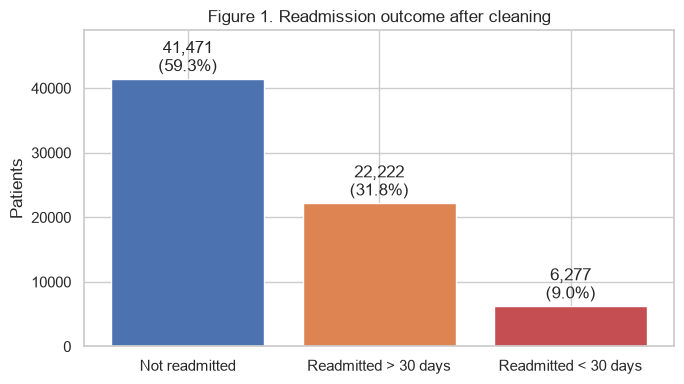

30-day readmission rate (readmit_30 = 1): 8.97%


In [18]:
# Class balance of the outcome (three-level label), with the share of each class on the bars.
order = ["NO", ">30", "<30"]
counts = df["readmitted"].value_counts().reindex(order)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Not readmitted", "Readmitted > 30 days", "Readmitted < 30 days"], counts,
              color=["#4C72B0", "#DD8452", "#C44E52"])
ax.bar_label(bars, labels=[f"{v:,}\n({v / len(df):.1%})" for v in counts], padding=2)
ax.set_title("Figure 1. Readmission outcome after cleaning")
ax.set_ylabel("Patients")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_target.png", dpi=120)
plt.show()
print(f"30-day readmission rate (readmit_30 = 1): {df['readmit_30'].mean():.2%}")

**Insight:** of the 69,970 cleaned patients, 59.3% were not readmitted, 31.8% came back after 30 days, and only 9.0% (6,277) within 30 days. The 30-day class is a 1-in-11 minority, so a model that always predicts "no" would already score 91% accuracy; accuracy alone is not a useful metric here.

### 4.2 Distributions of the numeric features

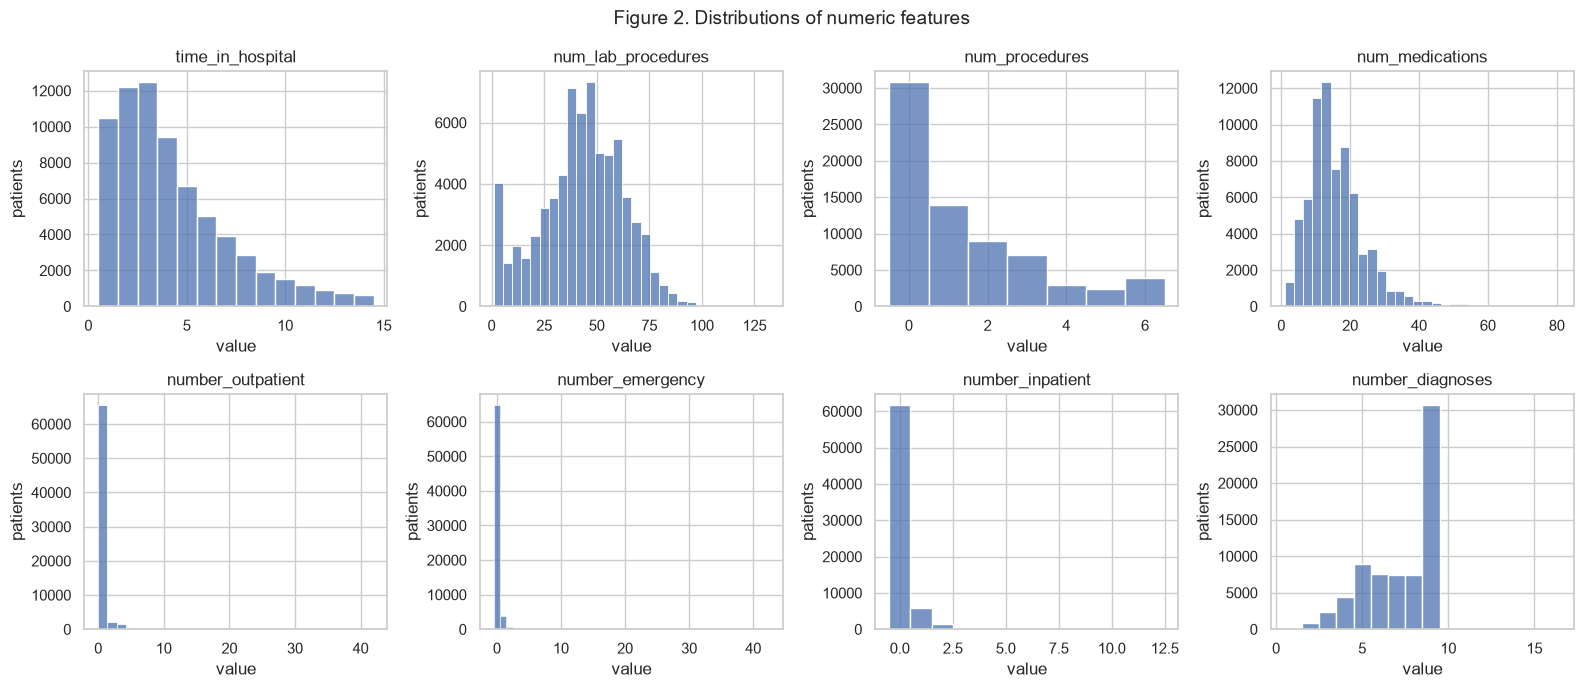

,mean,median,skew
time_in_hospital,4.27,3.0,1.18
num_lab_procedures,42.88,44.0,-0.22
num_procedures,1.43,1.0,1.23
num_medications,15.67,14.0,1.43
number_outpatient,0.28,0.0,9.70
number_emergency,0.10,0.0,21.23
number_inpatient,0.18,0.0,5.59
number_diagnoses,7.22,8.0,-0.72


In [19]:
# Histogram of each numeric count feature to see shape, skew and range.
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), NUM_COLS):
    discrete = df[c].nunique() <= 20           # one bar per value for small integer ranges
    sns.histplot(df[c], ax=ax, discrete=discrete, bins=None if discrete else 30, color="#4C72B0")
    ax.set_title(c)
    ax.set_xlabel("value")
    ax.set_ylabel("patients")
fig.suptitle("Figure 2. Distributions of numeric features", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_distributions.png", dpi=120)
plt.show()
df[NUM_COLS].agg(["mean", "median", "skew"]).T.round(2)

**Insight:** length of stay is right-skewed (mean 4.27 vs. median 3 days; half of all stays are 3 days or less), and so is `num_medications` (skew 1.43). The three prior-visit counts are extremely zero-inflated (skew 9.7, 21.2, 5.6). `num_lab_procedures` is roughly bell-shaped apart from a spike at the low end (2,254 patients with exactly 1 test), and `number_diagnoses` piles up at 9 (43.9% of patients, only 73 above 9), which looks like a recording cap.

### 4.3 Outliers

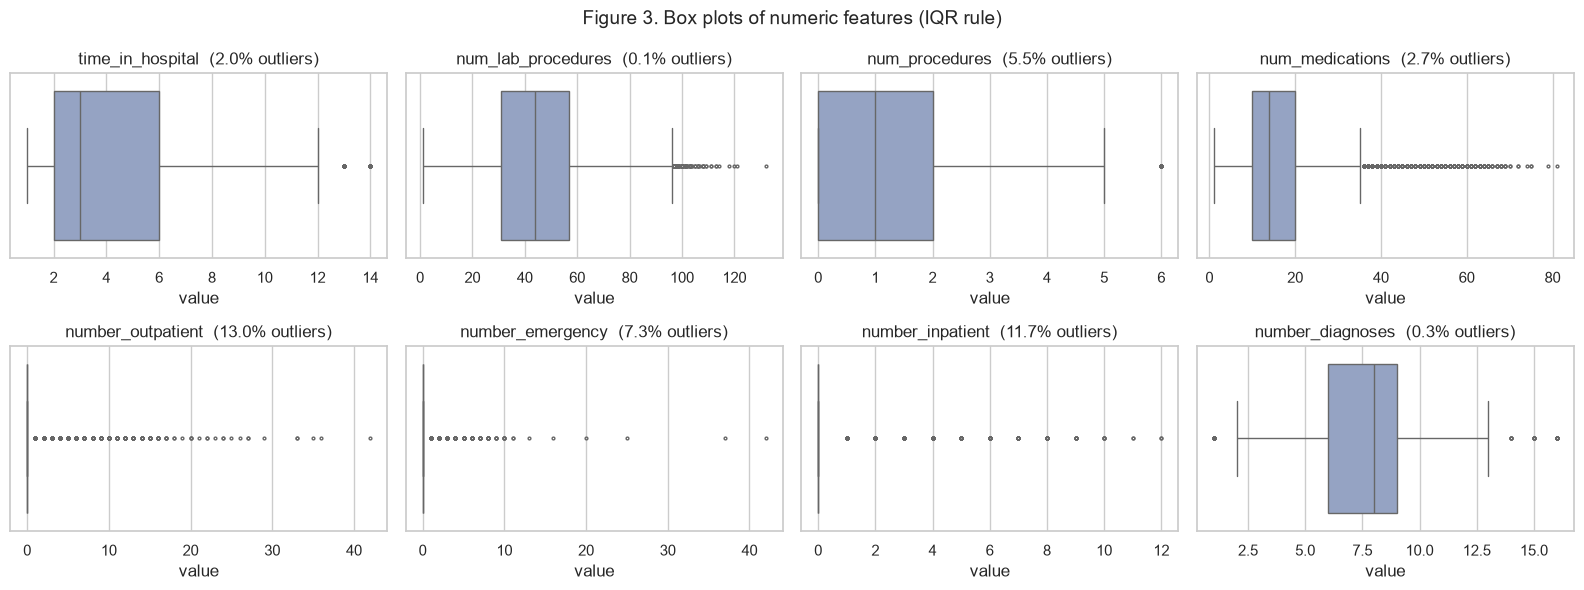

In [20]:
# Box plots show the IQR box and the points beyond the 1.5*IQR whiskers (the outliers from 3.4c).
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.ravel(), NUM_COLS):
    sns.boxplot(x=df[c], ax=ax, color="#8DA0CB", fliersize=2)
    ax.set_title(f"{c}  ({outlier_table.loc[c, 'outlier_%']}% outliers)")
    ax.set_xlabel("value")
fig.suptitle("Figure 3. Box plots of numeric features (IQR rule)", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_boxplots.png", dpi=120)
plt.show()

**Insight:** the IQR rule flags 13.0% of `number_outpatient`, 11.7% of `number_inpatient` and 7.3% of `number_emergency`, simply because their Q1 and Q3 are both 0. `num_medications` has 1,867 patients (2.7%) above the 35-drug fence, while `num_lab_procedures` has almost none (0.1%). These are kept (see 3.4c) and will be log-transformed for linear models.

### 4.4 Feature relationships: correlation

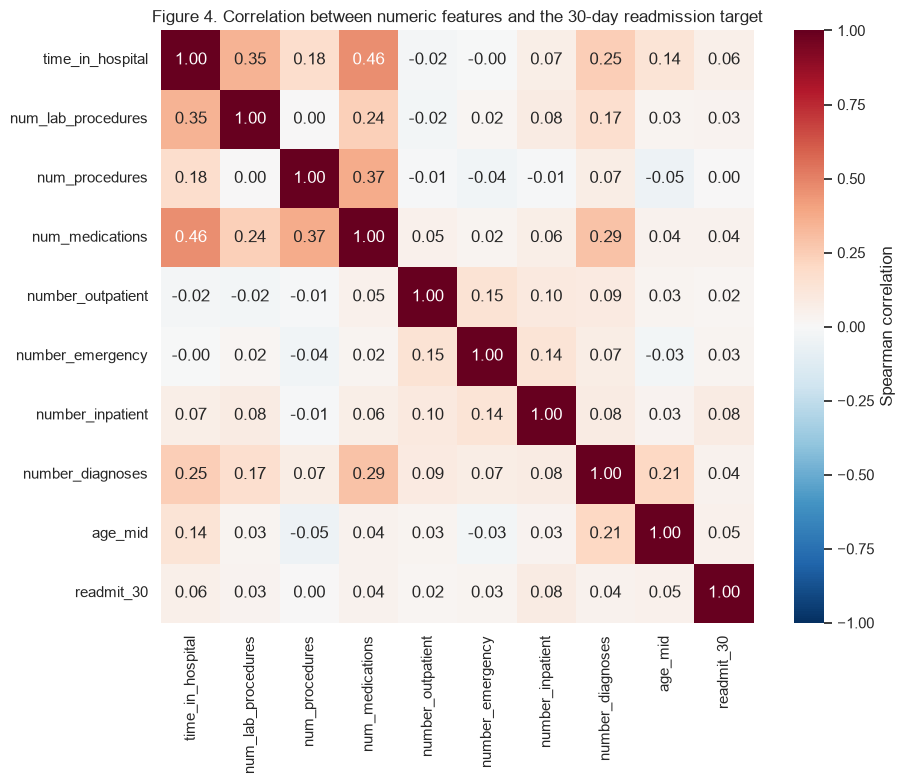

,number_inpatient,time_in_hospital,age_mid,number_diagnoses,num_medications,num_lab_procedures,number_emergency,number_outpatient,num_procedures
corr with readmit_30,0.085,0.06,0.048,0.043,0.043,0.032,0.03,0.016,0.004


In [21]:
# Spearman correlation (rank based) because most counts are skewed; includes age and the target.
corr_cols = NUM_COLS + ["age_mid", "readmit_30"]
corr = df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Spearman correlation"})
ax.set_title("Figure 4. Correlation between numeric features and the 30-day readmission target")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_correlation.png", dpi=120)
plt.show()
corr["readmit_30"].drop("readmit_30").sort_values(ascending=False).round(3).to_frame("corr with readmit_30").T

**Insight:** the strongest relationships are among the "workload" features: `num_medications` with `time_in_hospital` (0.46), with `num_procedures` (0.37), and `time_in_hospital` with `num_lab_procedures` (0.35). No pair exceeds 0.5, so multicollinearity is low. Every numeric feature correlates with `readmit_30` at 0.085 or less (`number_inpatient` is highest), so no single number explains readmission.

### 4.5 Relationships with the regression target (length of stay)

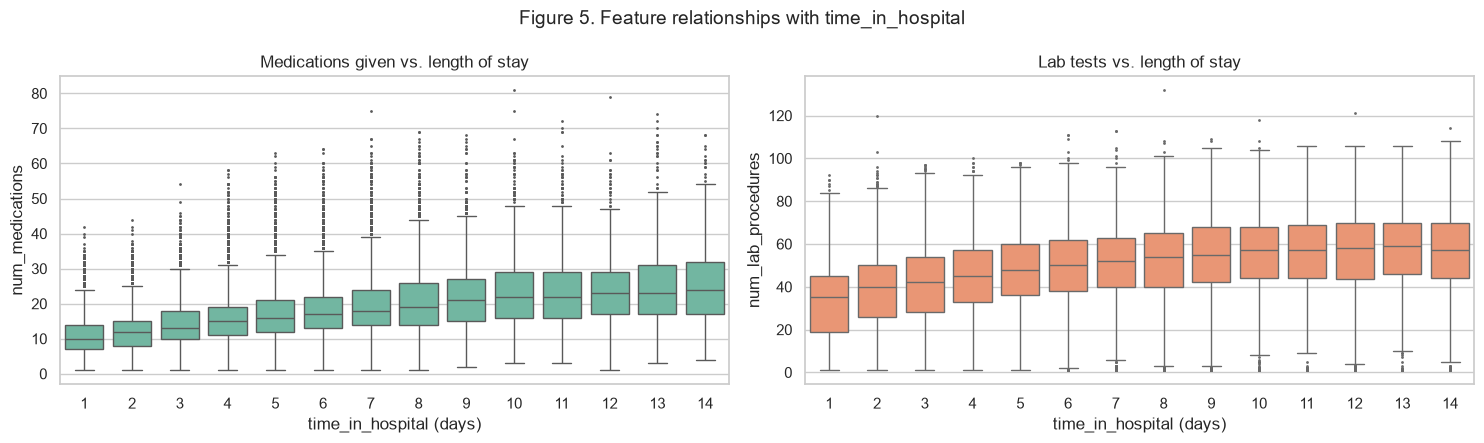

time_in_hospital,1,2,3,4,5,6,7,8,9,10,11,12,13,14
num_medications,10.0,12.0,13.0,15.0,16.0,17.0,18.0,19.0,21.0,22.0,22.0,23.0,23.0,24.0
num_lab_procedures,35.0,40.0,42.0,45.0,48.0,50.0,52.0,54.0,55.0,57.0,57.0,58.0,59.0,57.0


In [22]:
# How length of stay (future regression target) moves with medication and lab-test counts.
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=df, x="time_in_hospital", y="num_medications", ax=axes[0], color="#66C2A5", fliersize=1)
axes[0].set_title("Medications given vs. length of stay")
axes[0].set_xlabel("time_in_hospital (days)")
sns.boxplot(data=df, x="time_in_hospital", y="num_lab_procedures", ax=axes[1], color="#FC8D62", fliersize=1)
axes[1].set_title("Lab tests vs. length of stay")
axes[1].set_xlabel("time_in_hospital (days)")
fig.suptitle("Figure 5. Feature relationships with time_in_hospital", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig5_length_of_stay.png", dpi=120)
plt.show()
df.groupby("time_in_hospital")[["num_medications", "num_lab_procedures"]].median().T

**Insight:** the median number of medications rises steadily from 10 for a 1-day stay to 24 for a 14-day stay, and median lab tests rise from 35 to about 57. Both are strong candidates for the length-of-stay regression, but the wide boxes show a lot of variation they do not explain.

### 4.6 30-day readmission rate by key features

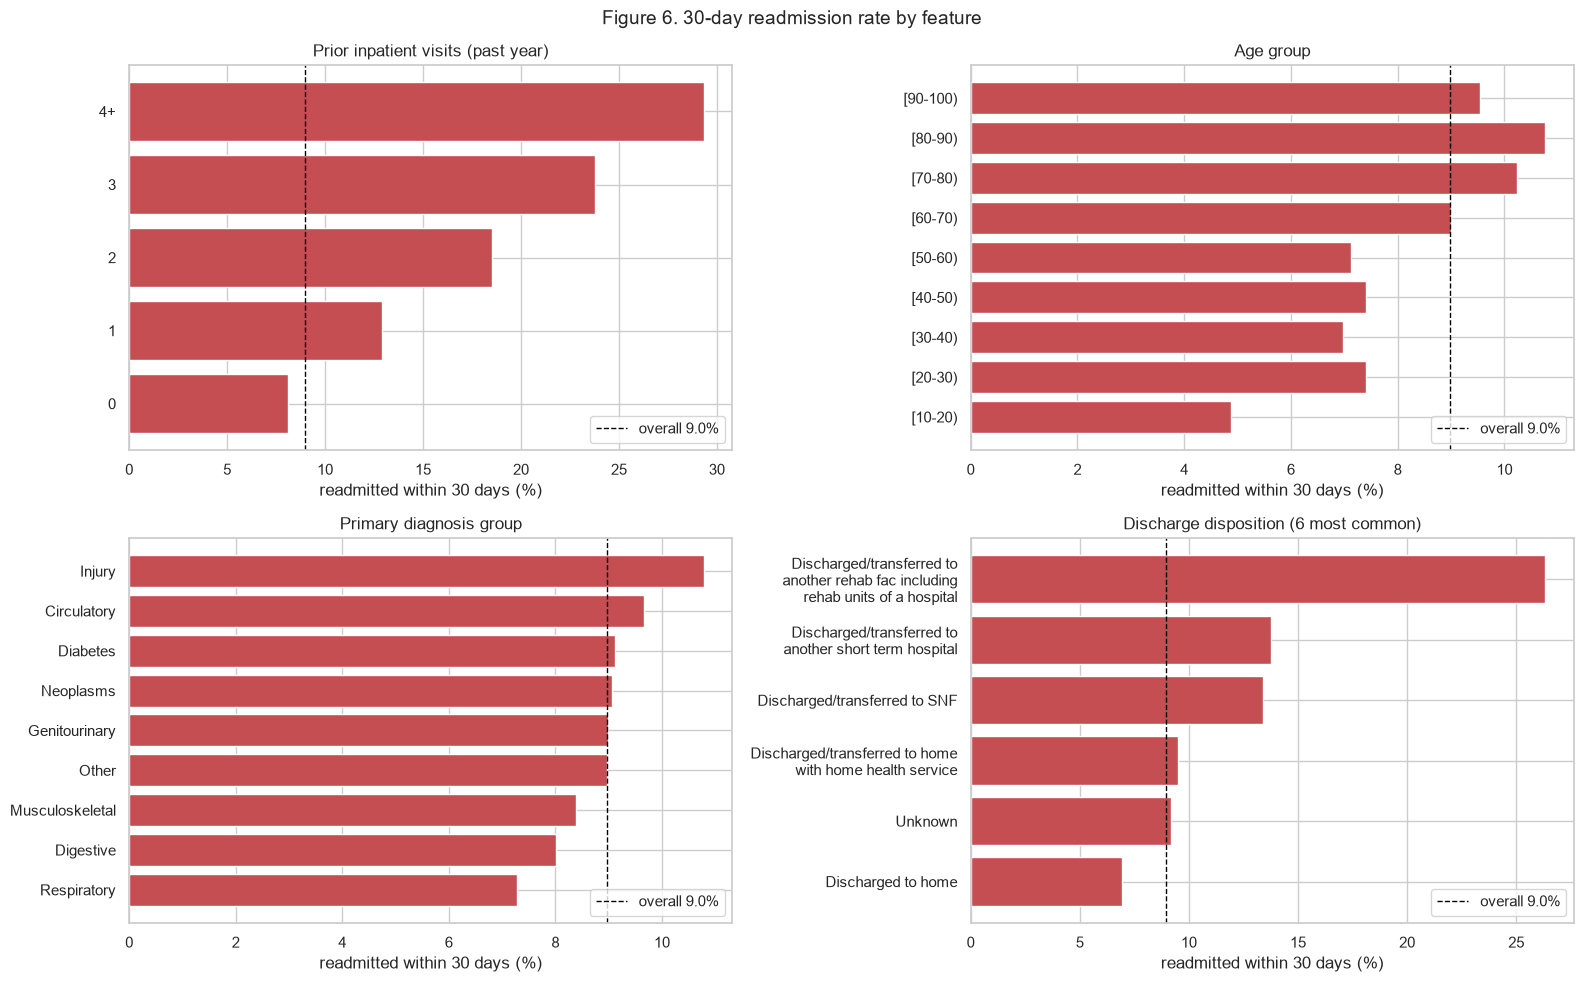

Prior inpatient visits (past year) {'0': '8.1% (n=61,779)', '1': '12.9% (n=5,794)', '2': '18.5% (n=1,501)', '3': '23.8% (n=463)', '4+': '29.3% (n=433)'}
Age group {'[10-20)': '4.9% (n=534)', '[20-30)': '7.4% (n=1,121)', '[30-40)': '7.0% (n=2,692)', '[40-50)': '7.4% (n=6,828)', '[50-60)': '7.1% (n=12,349)', '[60-70)': '9.0% (n=15,683)', '[70-80)': '10.2% (n=17,748)', '[80-90)': '10.8% (n=11,102)', '[90-100)': '9.5% (n=1,760)'}
Primary diagnosis group {'Respiratory': '7.3% (n=9,486)', 'Digestive': '8.0% (n=6,487)', 'Musculoskeletal': '8.4% (n=4,064)', 'Other': '9.0% (n=12,122)', 'Genitourinary': '9.0% (n=3,440)', 'Neoplasms': '9.1% (n=2,538)', 'Diabetes': '9.1% (n=5,748)', 'Circulatory': '9.7% (n=21,383)', 'Injury': '10.8% (n=4,692)'}
Discharge disposition (6 most common) {'Discharged to home': '6.9% (n=44,315)', 'Unknown': '9.2% (n=3,252)', 'Discharged/transferred to home with home health service': '9.5% (n=8,289)', 'Discharged/transferred to SNF': '13.4% (n=8,784)', 'Discharged/transfe

In [23]:
# Readmission rate per category, with groups under 200 patients hidden to avoid noisy rates.
import textwrap
def readmit_rate(col, min_n=200):
    t = df.groupby(col, observed=True)["readmit_30"].agg(rate="mean", patients="size")
    return t[t["patients"] >= min_n]

overall = df["readmit_30"].mean()
inpatient_bins = pd.cut(df["number_inpatient"], [-1, 0, 1, 2, 3, np.inf], labels=["0", "1", "2", "3", "4+"])
panels = [
    ("Prior inpatient visits (past year)", readmit_rate(inpatient_bins.rename("prior inpatient visits"))),
    ("Age group", readmit_rate("age")),
    ("Primary diagnosis group", readmit_rate("diag_1_group").sort_values("rate")),
    ("Discharge disposition (6 most common)",
     readmit_rate("discharge_disposition").nlargest(6, "patients").sort_values("rate")),
]
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, (title, t) in zip(axes.ravel(), panels):
    labels = [textwrap.fill(str(i), 30) for i in t.index]  # wrap long discharge labels
    ax.barh(labels, t["rate"] * 100, color="#C44E52")
    ax.axvline(overall * 100, ls="--", color="black", lw=1, label=f"overall {overall:.1%}")
    ax.set_title(title)
    ax.set_xlabel("readmitted within 30 days (%)")
    ax.legend(loc="lower right")
fig.suptitle("Figure 6. 30-day readmission rate by feature", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig6_readmission_rates.png", dpi=120)
plt.show()
for title, t in panels:
    print(title, {k: f"{r:.1%} (n={int(n):,})" for k, (r, n) in t[["rate", "patients"]].iterrows()})

In [24]:
# Lab-test and medication-change flags vs. readmission (small tables, no chart needed).
for col in ["A1Cresult", "max_glu_serum", "change", "diabetesMed"]:
    t = readmit_rate(col)
    print(f"{col:14s}", {k: f"{r:.1%} (n={int(n):,})" for k, (r, n) in t[["rate", "patients"]].iterrows()})

A1Cresult      {'>7': '8.6% (n=2,865)', '>8': '8.2% (n=6,239)', 'Norm': '8.6% (n=3,741)', 'Not tested': '9.1% (n=57,125)'}
max_glu_serum  {'>200': '10.9% (n=936)', '>300': '10.1% (n=712)', 'Norm': '9.8% (n=1,700)', 'Not tested': '8.9% (n=66,622)'}
change         {'Ch': '9.4% (n=31,489)', 'No': '8.6% (n=38,481)'}
diabetesMed    {'No': '7.5% (n=16,679)', 'Yes': '9.4% (n=53,291)'}


**Insight:** prior inpatient visits are the clearest signal: the 30-day rate climbs from 8.1% (no prior visits) to 12.9%, 18.5%, 23.8% and 29.3% (4+). Discharge destination matters too: 6.9% for patients sent home vs. 13.4% to a skilled nursing facility and 26.3% to a rehab facility. Risk also rises with age (7.1% at 50-60 to 10.8% at 80-90). Primary diagnosis spreads less (7.3% respiratory to 10.8% injury), and the A1C result barely changes the rate (8.2% to 9.1%).

### 4.7 Diabetes medication usage

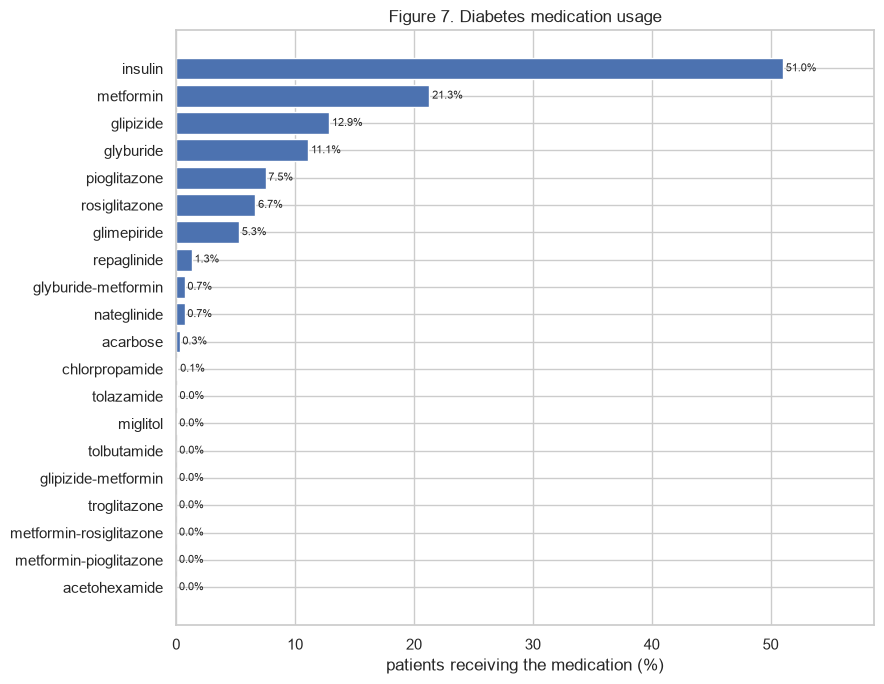

20 medication columns; used by >= 1% of patients: 8


,insulin,metformin,glipizide,glyburide,pioglitazone,rosiglitazone,glimepiride,repaglinide
% of patients,51.0,21.3,12.9,11.1,7.5,6.7,5.3,1.3


In [25]:
# Share of patients on each medication (any value other than "No"). This shows which
# medication columns are rich enough for association-rule mining in Deliverable 4.
MED_COLS = [c for c in df.columns[df.columns.get_loc("max_glu_serum"):] if set(df[c].unique()) <= {"No", "Steady", "Up", "Down"}]
usage = (df[MED_COLS] != "No").mean().sort_values(ascending=True) * 100
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(usage.index, usage.values, color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2, fontsize=8)
ax.set_xlabel("patients receiving the medication (%)")
ax.set_title("Figure 7. Diabetes medication usage")
ax.set_xlim(0, usage.max() * 1.15)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig7_medications.png", dpi=120)
plt.show()
print(f"{len(MED_COLS)} medication columns; used by >= 1% of patients: {(usage >= 1).sum()}")
usage.sort_values(ascending=False).head(8).round(1).to_frame("% of patients").T

**Insight:** insulin is used by 51.0% of patients, then metformin (21.3%), glipizide (12.9%), glyburide (11.1%), pioglitazone (7.5%), rosiglitazone (6.7%), glimepiride (5.3%) and repaglinide (1.3%). Only these 8 of the 20 medication columns reach 1% of patients; the other 12 are almost always "No".

## 5. Insights and How They Guide Modeling

1. **Class imbalance (9.0% positive).** Use a stratified train/test split, class weights or resampling applied to the training set only, and judge models by recall, F1 and ROC-AUC/PR-AUC rather than accuracy.
2. **Likely predictors.** Prior inpatient visits, discharge disposition, age and length of stay show the clearest differences in readmission. Correlations with the target are weak (0.085 or less), so non-linear models (decision trees, random forests, gradient boosting) should do better than a plain linear model. A combined "total prior visits" feature is worth testing.
3. **Leakage.** One encounter per patient already prevents the same person appearing in train and test. The 3-class `readmitted` column must be dropped when `readmit_30` is the target, and scaling or resampling must be fitted on the training split only. For the length-of-stay regression, medication, lab and procedure counts are recorded *during* the stay, so they can explain a stay but cannot predict it at admission.
4. **Encoding.** One-hot encode the nominal columns (race, gender, admission type and source, discharge disposition, specialty, diagnosis groups). Treat age (`age_mid`) and medication dose changes (No, Down, Steady, Up) as ordinal, and `change`/`diabetesMed` as binary.
5. **Scaling and skew.** Apply `log1p` to the zero-inflated visit counts and standardize numeric features for linear models and for k-means clustering, which is distance based.
6. **Association rules.** Mine medication combinations from the 8 drugs used by at least 1% of patients, with minimum support near 1%; the 12 rare medication columns add almost no transactions.

## Reference

Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J., & Clore, J. N. (2014). Impact of HbA1c measurement on hospital readmission rates: Analysis of 70,000 clinical database patient records. *BioMed Research International, 2014*, Article 781670. https://doi.org/10.1155/2014/781670